In [194]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [195]:
data=pd.read_csv("customer_behavior.csv")
data.head(5)

,CustomerID,Gender,Region,PurchaseAmount,ProductCategory,Churn,CampaignGroup
0,1001,Male,South,256.07,Fashion,No,A
1,1002,Female,South,NaN,Electronics,Yes,B
2,1003,Female,West,1194.41,Fashion,No,A
3,1004,Female,South,413.06,Grocery,No,A
4,1005,Male,West,1556.32,Fashion,Yes,A


In [196]:
data=data.dropna()
data.shape

(3715, 7)

In [197]:
print("Average of PurchaseAmount:",data["PurchaseAmount"].mean())   #1
print("Median of PurchaseAmount:",data["PurchaseAmount"].median())
print("Mode of PurchaseAmount:",data["PurchaseAmount"].mode()[0])

Average of PurchaseAmount: 1001.1536716016151
Median of PurchaseAmount: 996.15
Mode of PurchaseAmount: 0.0


<Axes: ylabel='PurchaseAmount'>

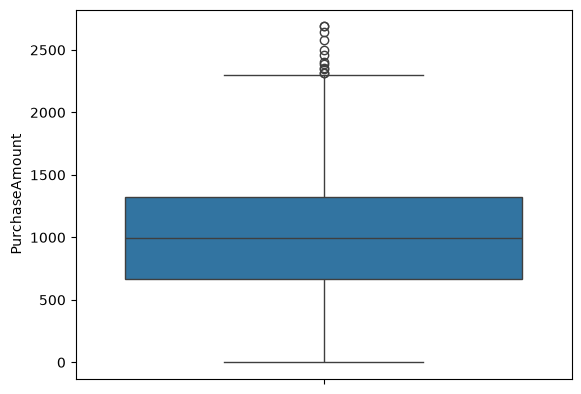

In [198]:
sns.boxplot(data=data["PurchaseAmount"])       #2

In [199]:
q1,q3=data["PurchaseAmount"].quantile([0.25, 0.75])
iqr=q3-q1
lower_bound=q1-1.5*iqr
upper_bound=q3+1.5*iqr
outliers=data[(data["PurchaseAmount"]<lower_bound) | (data["PurchaseAmount"]>upper_bound)]
print("Count of outliers: ",len(outliers))

Count of outliers:  12


In [200]:
print("Skewness: ",data["PurchaseAmount"].skew())             #3
print("Kurtosis: ",data["PurchaseAmount"].kurtosis())

Skewness:  0.09137463187452266
Kurtosis:  -0.28400835886052134


In [201]:
from scipy import stats

In [202]:
males=data[data["Gender"]=="Male"]["PurchaseAmount"]            #4
females=data[data["Gender"]=="Female"]["PurchaseAmount"]
t_stat,p_value=stats.ttest_ind(males,females)
if p_value < 0.05:
    print("There is a significant difference in spending between male and female customers")
else:
    print("No significant difference in spending between male and female customers")

No significant difference in spending between male and female customers


In [203]:
from scipy.stats import chi2_contingency                  #5
df=pd.crosstab(data["ProductCategory"],data["Churn"])
chi2, p_value, dof, expected = chi2_contingency(df)
if p_value < 0.05:
    print("Significant Association between ProductCategory and customer churn")
else:
    print("No Significant Association between ProductCategory and customer churn")

No Significant Association between ProductCategory and customer churn


In [204]:
data["Region"].value_counts()

Region
East     949
South    946
North    925
West     895
Name: count, dtype: int64

In [205]:
from scipy.stats import f_oneway                          #6
north=data[data["Region"]=="North"]["PurchaseAmount"]
south=data[data["Region"]=="South"]["PurchaseAmount"]
east=data[data["Region"]=="East"]["PurchaseAmount"]
west=data[data["Region"]=="West"]["PurchaseAmount"]
f_stat, p_value = f_oneway(north,south,east,west)
if p_value < 0.05:
    print("At least one group mean is significantly different")
else:
    print("No significant difference found")

No significant difference found


In [206]:
from statsmodels.stats.proportion import proportions_ztest     #7

campain_a=data[data["CampaignGroup"]=='A']["PurchaseAmount"]
campain_b=data[data["CampaignGroup"]=='B']["PurchaseAmount"]
mean_a=campain_a.mean()
mean_b=campain_b.mean()
conversions=[mean_a,mean_b]

visitors=[len(campain_a),len(campain_b)]

z_stat, p_value=proportions_ztest(count=conversions,nobs=visitors)

print("Campain A Conversion Rate:", conversions[0] / visitors[0] * 100, "%")
print("Campain B Conversion Rate:", conversions[1] / visitors[1] * 100, "%")

if p_value < 0.05:
    print("Significant difference between Campain A and Campain B")
else:
    print("No statistically significant difference between Campain A and Campain B")

Campain A Conversion Rate: 54.34508248403229 %
Campain B Conversion Rate: 53.44921962089402 %
No statistically significant difference between Campain A and Campain B


Text(0, 0.5, 'Frequency')

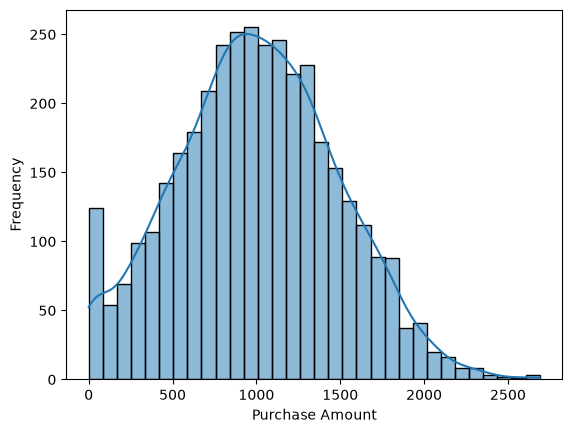

In [207]:
sns.histplot(data=data["PurchaseAmount"],kde="True")    #8
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")

In [208]:
print("Right-skewed tail present in the graph: Not a normal distribution")

Right-skewed tail present in the graph: Not a normal distribution


       #9
CLT states that if you take large enough random samples (n>=30) from any population distribution—regardless of how skewed or non-normal it is—the distribution of the sample means will approximate a smooth, symmetric bell curve (Normal Distribution).

Applied to PurchaseAmount: Even if individual customer purchases range from 0 to 2,500 with a heavy skew, if you repeatedly draw samples of, say, 50 or 100 customers and calculate their average spend, those averages will follow a normal distribution.   

In [210]:
sample_mean=data["PurchaseAmount"].mean()        #10
size=len(data["PurchaseAmount"])

std_error=stats.sem(data["PurchaseAmount"])

confidence_interval=stats.t.interval(0.95,df=size-1,loc=mean,scale=std_error)

print(f"Sample Average: {sample_mean:.2f}")
print(f"95% Confidence Interval: {confidence_interval[0]:.2f},{confidence_interval[1]:.2f}")

Sample Average: 1001.15
95% Confidence Interval: 985.60,1016.71
